# Q3 — Measure & Record: Speed, Accuracy, and Model Metrics

**Task:** For each detector, measure and record:
- Detection Speed (FPS)
- Accuracy / Confidence Scores on different object types
- Model size and inference time per frame

**Models compared:** YOLOv3u · YOLOv8n · RT-DETR-L

In [1]:
import os, time, gc
from pathlib import Path
from collections import defaultdict
import numpy as np
import cv2
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from ultralytics import YOLO, RTDETR

get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
get_ipython().run_line_magic("matplotlib", "inline")

OUT    = Path("outputs_q3"); OUT.mkdir(exist_ok=True)
IMAGES = sorted(Path("images").glob("*.jpg"))
CONF   = 0.25
N_RUNS = 10    # repeated runs per image for stable timing

print("Images:", [p.name for p in IMAGES])
print("Timing runs per image:", N_RUNS)

Images: ['bus.jpg', 'bus2.jpg', 'zidane.jpg', 'zidane2.jpg']
Timing runs per image: 10


## 1 — Load Models & Collect Static Properties

In [2]:
print("Loading models …")
models = {
    "YOLOv3u"   : YOLO("yolov3u.pt"),
    "YOLOv8n"   : YOLO("yolov8n.pt"),
    "RT-DETR-L" : RTDETR("rtdetr-l.pt"),
}

static = {}
for name, mdl in models.items():
    weight_file = {"YOLOv3u":"yolov3u.pt","YOLOv8n":"yolov8n.pt","RT-DETR-L":"rtdetr-l.pt"}[name]
    n_params = sum(p.numel() for p in mdl.model.parameters())
    file_mb  = Path(weight_file).stat().st_size / 1e6
    static[name] = {"params_M": n_params/1e6, "file_MB": file_mb}
    print(f"  {name:<14}  params={n_params/1e6:.2f}M  file={file_mb:.1f}MB")

Loading models …
  YOLOv3u         params=103.75M  file=207.9MB
  YOLOv8n         params=3.16M  file=6.5MB
  RT-DETR-L       params=32.97M  file=66.5MB


## 2 — Timing Benchmark (N_RUNS iterations per image)

We warm-up each model with one forward pass, then run N_RUNS timed inference
calls and record min/mean/max latency.

In [3]:
timing = defaultdict(list)      # {model_name: [ms, ms, ...]}
det_counts = defaultdict(list)  # {model_name: [n_dets, ...]}
all_dets   = defaultdict(list)  # {model_name: [{"label","conf"}, ...]}

for img_path in IMAGES:
    frame = cv2.imread(str(img_path))

    for mname, mdl in models.items():
        # warm-up pass (not counted)
        _ = mdl(frame, verbose=False, conf=CONF)

        # timed runs
        times_i = []
        for _ in range(N_RUNS):
            t0  = time.perf_counter()
            res = mdl(frame, verbose=False, conf=CONF)
            times_i.append((time.perf_counter() - t0) * 1000)

        timing[mname].extend(times_i)

        # collect detections from last run
        boxes = res[0].boxes
        n_det = 0
        if boxes is not None:
            for box in boxes:
                conf = float(box.conf[0])
                if conf >= CONF:
                    cls_id = int(box.cls[0])
                    all_dets[mname].append({
                        "label": mdl.names[cls_id],
                        "conf" : conf,
                        "image": img_path.name,
                    })
                    n_det += 1
        det_counts[mname].append(n_det)
        print(f"  {mname:<14} {img_path.name:<20} mean={np.mean(times_i):.1f}ms  "
              f"dets={n_det}")

  YOLOv3u        bus.jpg              mean=5921.5ms  dets=6
  YOLOv8n        bus.jpg              mean=171.8ms  dets=6
  RT-DETR-L      bus.jpg              mean=3140.7ms  dets=9
  YOLOv3u        bus2.jpg             mean=5933.0ms  dets=6
  YOLOv8n        bus2.jpg             mean=686.1ms  dets=6
  RT-DETR-L      bus2.jpg             mean=1927.6ms  dets=9
  YOLOv3u        zidane.jpg           mean=2597.2ms  dets=3
  YOLOv8n        zidane.jpg           mean=281.0ms  dets=3
  RT-DETR-L      zidane.jpg           mean=2578.8ms  dets=4
  YOLOv3u        zidane2.jpg          mean=2914.4ms  dets=3
  YOLOv8n        zidane2.jpg          mean=158.1ms  dets=3
  RT-DETR-L      zidane2.jpg          mean=2209.6ms  dets=4


## 3 — Speed Summary Table (FPS & Latency)

In [4]:
print(f"{'Model':<14} {'Min ms':>8} {'Mean ms':>9} {'Max ms':>8} {'FPS':>8} {'Dets/frame':>12}")
print("=" * 65)
speed_data = {}
for name in models:
    t = timing[name]
    mn, mu, mx = min(t), np.mean(t), max(t)
    fps = 1000.0 / mu
    avg_dets = np.mean(det_counts[name])
    speed_data[name] = {"min": mn, "mean": mu, "max": mx, "fps": fps, "avg_dets": avg_dets}
    print(f"{name:<14} {mn:>8.1f} {mu:>9.1f} {mx:>8.1f} {fps:>8.1f} {avg_dets:>12.1f}")

Model            Min ms   Mean ms   Max ms      FPS   Dets/frame
YOLOv3u          1949.8    4341.5  12357.0      0.2          4.5
YOLOv8n           108.2     324.2   1958.9      3.1          4.5
RT-DETR-L        1417.7    2464.2   4165.1      0.4          6.5


## 4 — Model Size Comparison

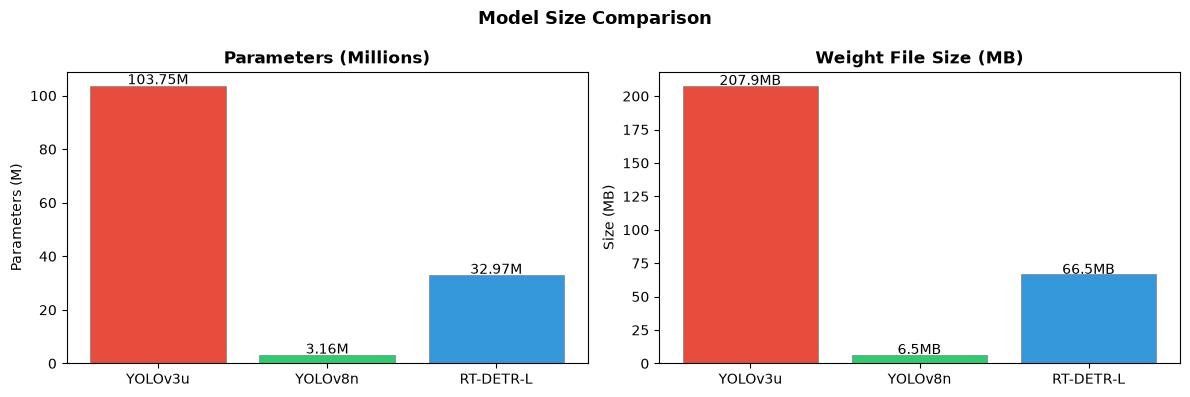

Saved → outputs_q3/q3_model_sizes.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

names = list(models.keys())
params = [static[n]["params_M"] for n in names]
sizes  = [static[n]["file_MB"]  for n in names]
colors = ["#e74c3c","#2ecc71","#3498db"]

axes[0].bar(names, params, color=colors, edgecolor="grey", linewidth=0.5)
for i,(v,n) in enumerate(zip(params,names)):
    axes[0].text(i, v+0.5, f"{v:.2f}M", ha="center", fontsize=10)
axes[0].set_title("Parameters (Millions)", fontweight="bold")
axes[0].set_ylabel("Parameters (M)")

axes[1].bar(names, sizes, color=colors, edgecolor="grey", linewidth=0.5)
for i,(v,n) in enumerate(zip(sizes,names)):
    axes[1].text(i, v+0.5, f"{v:.1f}MB", ha="center", fontsize=10)
axes[1].set_title("Weight File Size (MB)", fontweight="bold")
axes[1].set_ylabel("Size (MB)")

plt.suptitle("Model Size Comparison", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT / "q3_model_sizes.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → outputs_q3/q3_model_sizes.png")

## 5 — Inference Speed Comparison (FPS & Latency)

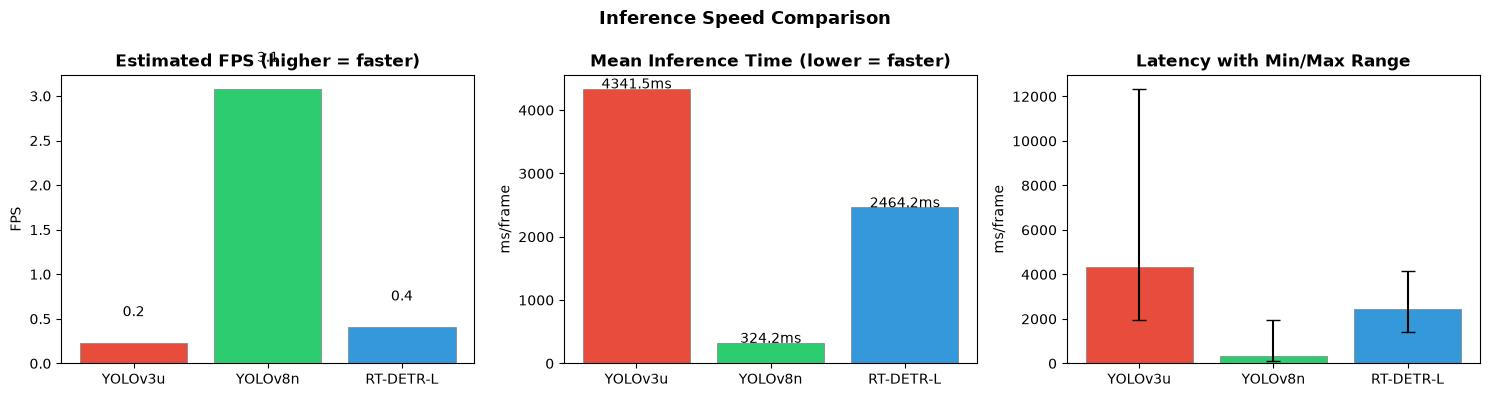

Saved → outputs_q3/q3_inference_speed.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

fps_vals  = [speed_data[n]["fps"]  for n in names]
mean_vals = [speed_data[n]["mean"] for n in names]
min_vals  = [speed_data[n]["min"]  for n in names]
max_vals  = [speed_data[n]["max"]  for n in names]

# FPS
axes[0].bar(names, fps_vals, color=colors, edgecolor="grey", linewidth=0.5)
for i,v in enumerate(fps_vals):
    axes[0].text(i, v+0.3, f"{v:.1f}", ha="center", fontsize=10)
axes[0].set_title("Estimated FPS (higher = faster)", fontweight="bold")
axes[0].set_ylabel("FPS")

# Mean latency
axes[1].bar(names, mean_vals, color=colors, edgecolor="grey", linewidth=0.5)
for i,v in enumerate(mean_vals):
    axes[1].text(i, v+0.5, f"{v:.1f}ms", ha="center", fontsize=10)
axes[1].set_title("Mean Inference Time (lower = faster)", fontweight="bold")
axes[1].set_ylabel("ms/frame")

# Latency range
xerr_lo = [speed_data[n]["mean"] - speed_data[n]["min"] for n in names]
xerr_hi = [speed_data[n]["max"]  - speed_data[n]["mean"] for n in names]
axes[2].bar(names, mean_vals, color=colors, edgecolor="grey", linewidth=0.5,
            yerr=[xerr_lo, xerr_hi], capsize=5)
axes[2].set_title("Latency with Min/Max Range", fontweight="bold")
axes[2].set_ylabel("ms/frame")

plt.suptitle("Inference Speed Comparison", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT / "q3_inference_speed.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → outputs_q3/q3_inference_speed.png")

## 6 — Confidence Scores by Object Class

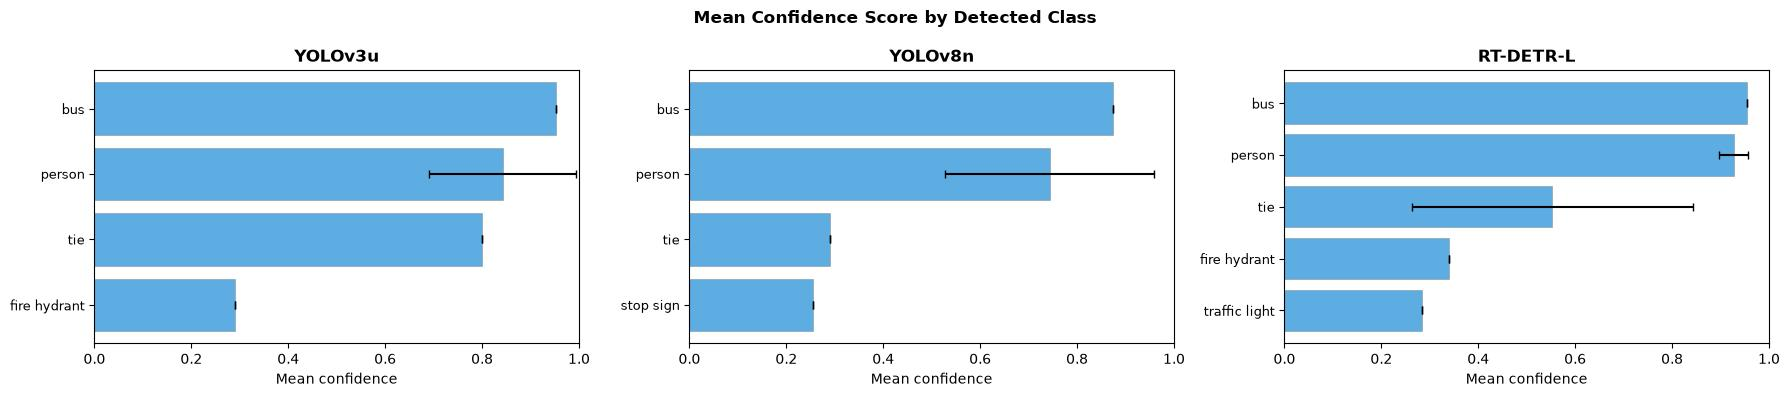

Saved → outputs_q3/q3_confidence_by_class.png


In [7]:
# Per-class confidence for each model
fig, axes = plt.subplots(1, len(names), figsize=(6*len(names), 4), sharey=False)

for ax, mname in zip(axes, names):
    dets = all_dets[mname]
    if not dets:
        ax.text(0.5, 0.5, "No detections", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(mname)
        continue

    from collections import defaultdict as dd
    class_confs = dd(list)
    for d in dets:
        class_confs[d["label"]].append(d["conf"])
    classes = sorted(class_confs.keys(), key=lambda c: -np.mean(class_confs[c]))
    means   = [np.mean(class_confs[c]) for c in classes]
    stds    = [np.std(class_confs[c])  for c in classes]

    y_pos = np.arange(len(classes))
    ax.barh(y_pos, means, xerr=stds, color="#3498db", edgecolor="grey",
            linewidth=0.4, capsize=3, alpha=0.8)
    ax.set_yticks(y_pos); ax.set_yticklabels(classes, fontsize=9)
    ax.set_xlabel("Mean confidence")
    ax.set_title(f"{mname}", fontweight="bold")
    ax.set_xlim(0, 1)
    ax.invert_yaxis()

plt.suptitle("Mean Confidence Score by Detected Class", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT / "q3_confidence_by_class.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → outputs_q3/q3_confidence_by_class.png")

## 7 — Comprehensive Summary Table

In [8]:
print("\n" + "="*72)
print("  COMPREHENSIVE DETECTOR METRICS SUMMARY")
print("="*72)
print(f"  {'Metric':<30} {'YOLOv3u':>12} {'YOLOv8n':>12} {'RT-DETR-L':>12}")
print("-"*72)

rows = [
    ("Parameters (M)",    "params_M",   "static",  ".2f"),
    ("Weight file (MB)",  "file_MB",    "static",  ".1f"),
    ("Min latency (ms)",  "min",        "speed",   ".1f"),
    ("Mean latency (ms)", "mean",       "speed",   ".1f"),
    ("Max latency (ms)",  "max",        "speed",   ".1f"),
    ("Estimated FPS",     "fps",        "speed",   ".1f"),
    ("Avg dets/frame",    "avg_dets",   "speed",   ".1f"),
]

for label, key, src, fmt in rows:
    vals = []
    for name in names:
        d = static[name] if src == "static" else speed_data[name]
        vals.append(d[key])
    line = f"  {label:<30}"
    for v in vals:
        line += f" {v:>12{fmt}}"
    print(line)

# Mean confidence per model
print("-"*72)
for name in names:
    dets = all_dets[name]
    mc = np.mean([d["conf"] for d in dets]) if dets else 0
    print(f"  {'Mean confidence':30} → {name}: {mc:.4f}")


  COMPREHENSIVE DETECTOR METRICS SUMMARY
  Metric                              YOLOv3u      YOLOv8n    RT-DETR-L
------------------------------------------------------------------------
  Parameters (M)                       103.75         3.16        32.97
  Weight file (MB)                      207.9          6.5         66.5
  Min latency (ms)                     1949.8        108.2       1417.7
  Mean latency (ms)                    4341.5        324.2       2464.2
  Max latency (ms)                    12357.0       1958.9       4165.1
  Estimated FPS                           0.2          3.1          0.4
  Avg dets/frame                          4.5          4.5          6.5
------------------------------------------------------------------------
  Mean confidence                → YOLOv3u: 0.7886
  Mean confidence                → YOLOv8n: 0.6533
  Mean confidence                → RT-DETR-L: 0.7193


C:\Users\Hp Elitebook 840 G3\AppData\Local\Temp\ipykernel_22508\2899951572.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(names, rotation=15, ha="right")
C:\Users\Hp Elitebook 840 G3\AppData\Local\Temp\ipykernel_22508\2899951572.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(names, rotation=15, ha="right")
C:\Users\Hp Elitebook 840 G3\AppData\Local\Temp\ipykernel_22508\2899951572.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(names, rotation=15, ha="right")
C:\Users\Hp Elitebook 840 G3\AppData\Local\Temp\ipykernel_22508\2899951572.py:15: UserWarning: set_tick

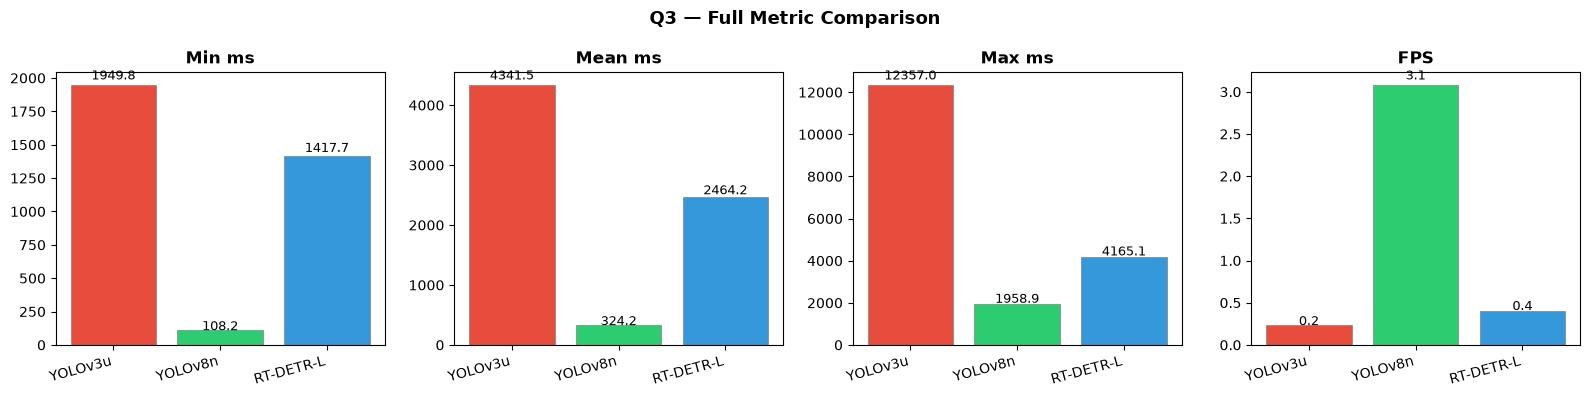

Saved → outputs_q3/q3_full_metrics.png


In [9]:
# Final bar chart: all 3 speed metrics side-by-side
metrics = ["Min ms","Mean ms","Max ms","FPS"]
vals_per_metric = [
    [speed_data[n]["min"]  for n in names],
    [speed_data[n]["mean"] for n in names],
    [speed_data[n]["max"]  for n in names],
    [speed_data[n]["fps"]  for n in names],
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, metric, vals in zip(axes, metrics, vals_per_metric):
    ax.bar(names, vals, color=colors, edgecolor="grey", linewidth=0.5)
    for i,v in enumerate(vals): ax.text(i, v*1.02, f"{v:.1f}", ha="center", fontsize=9)
    ax.set_title(metric, fontweight="bold")
    ax.set_xticklabels(names, rotation=15, ha="right")

plt.suptitle("Q3 — Full Metric Comparison", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT / "q3_full_metrics.png", dpi=90, bbox_inches="tight")
plt.show()
print("Saved → outputs_q3/q3_full_metrics.png")